# 02 — Advanced models, each with a business question and a baseline

The computation lives in `src/p2p/analysis/` and runs with `p2p analyse`. This notebook reads the
results and explains them. Every model is judged on later data it never saw, against something
simple a team could use today.

In [1]:
import json

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

from p2p import config

con = duckdb.connect(str(config.DB_PATH), read_only=True)
q = lambda sql: con.execute(sql).df()  # noqa: E731
m = json.loads((config.REPORTS / "metrics.json").read_text())

COBALT, AMBER, TEAL, GREY = "#5A6CF0", "#E39B2D", "#2BB39E", "#8A93A3"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12})


def save(fig, name):
    fig.savefig(config.FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Survival analysis: how long does payment really take?

Averaging paid items ignores everything still unpaid, and those are the slow ones. Survival models
treat an unpaid item as "at least this long". Deleted items are censored at deletion.

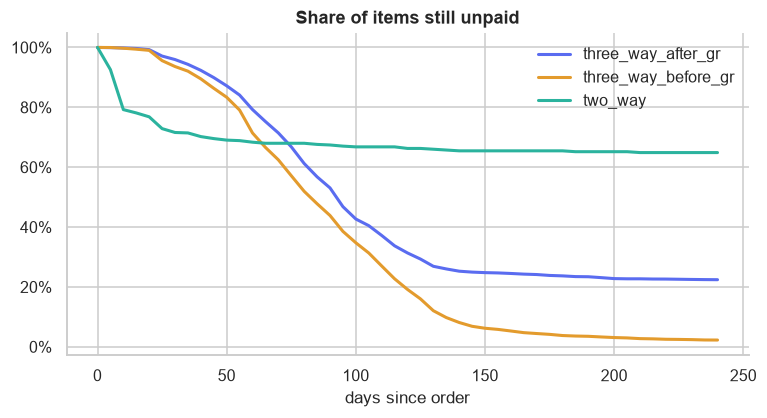

In [2]:
km = q("select * from analytics.km_curves where day <= 240")
fig, ax = plt.subplots(figsize=(8, 3.8))
for (flow, g), c in zip(km.groupby("flow"), [COBALT, AMBER, TEAL], strict=False):
    ax.plot(g["day"], g["share_unpaid"], color=c, lw=2, label=flow)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("days since order")
ax.set_title("Share of items still unpaid")
ax.legend(frameon=False)
save(fig, "model_km")

In [3]:
q("select * from analytics.survival_scores")

,model,concordance,aic
0,Weibull AFT,0.803556,382939.601218
1,Log-logistic AFT,0.822943,367633.498846
2,Flow median (baseline),0.508975,NaN


In [4]:
q("select * from analytics.time_ratios where p < 0.01 order by time_ratio desc")

,covariate,time_ratio,ci_low,ci_high,p
0,flow_two_way,7.853792,6.263611,9.847684,2.649401e-71
1,item_type_Subcontracting,2.195288,2.080041,2.316921,1.225768e-179
2,spend_area_Logistics,1.670640,1.512701,1.845068,4.125167e-24
3,item_type_Service,1.633688,1.504732,1.773695,1.274922e-31
4,vendor_prior_rework,1.294370,1.260999,1.328624,1.632991e-83
5,vendor_prior_days,1.213595,1.204641,1.222615,0.000000e+00
6,item_type_Third-party,1.095526,1.059161,1.133139,1.176552e-07
7,flow_three_way_after_gr,1.041248,1.014456,1.068748,2.372625e-03
8,doc_items,1.004860,1.004655,1.005064,0.000000e+00
9,log_prior_items,0.958555,0.956720,0.960393,0.000000e+00


A time ratio of 1.3 means payment takes 30% longer. These are associations, not causes. Vendor
history stands out: each extra month in a vendor's past payment time adds about 20%, which fits
payment terms the log doesn't record. A vendor's history largely stands in for its contract.

### Cash-out forecast
Summing each open item's chance of being paid soon gives a cash forecast from the open book.
Backtest: stand at an earlier date, fit on only what was known then, forecast 30 days.

In [5]:
q("select as_of, forecast_eur, actual_eur, naive_last_period_eur, open_items from analytics.cash_backtest order by as_of")

,as_of,forecast_eur,actual_eur,naive_last_period_eur,open_items
0,2018-09-15,7.298778e+07,69505618.0,71374003.0,55580
1,2018-10-15,6.549059e+07,62816687.0,69736182.0,52344
2,2018-11-15,6.302185e+07,62120977.0,64526364.0,55734


The forecast covers lines already on the book. Lines both ordered and paid inside the window aren't
in it, and the "actual" column excludes them for the same reason. The naive column is total payments
in the previous 30 days, so it's a fair baseline but not an identical measure.

## 2. Causal inference: does rework cause delay?

Changed orders are paid later. Does the change cause that? Three traps need handling:

* **Confounding**: changed orders differ in vendor, value and spend area. Double machine learning
  adjusts with flexible models, cross-fitted to avoid overfitting bias.
* **Immortal-time bias**: slow orders have longer to be changed. So the cohort is orders still
  unpaid at day 14, and treatment means a change inside those 14 days.
* **Censoring**: the outcome is unpaid days in the next 180, and every order has that follow-up.

In [6]:
e = q("select * from analytics.causal_effects")
e[["treatment", "n", "treated", "naive_diff_days", "dml_effect_days", "ci_low", "ci_high", "p_value", "placebo_effect_days", "share_trimmed"]]

,treatment,n,treated,naive_diff_days,dml_effect_days,ci_low,ci_high,p_value,placebo_effect_days,share_trimmed
0,any_change,108383,7785,5.060783,-0.086789,-1.594106,1.420528,0.910146,0.481950,0.137902
1,price_change,63189,2946,2.309814,0.958576,-2.103318,4.020469,0.539473,-0.183698,0.497383
2,quantity_change,90586,4597,6.982312,0.022144,-2.835149,2.879437,0.987880,0.413133,0.279462
3,"any_change, excluding later deletions",108772,7759,5.043288,-0.651135,-2.070626,0.768355,0.368614,0.088462,0.128813


In [7]:
q("select segment, n, treated, naive_diff_days, dml_effect_days, ci_low, ci_high from analytics.causal_segments")

,segment,n,treated,naive_diff_days,dml_effect_days,ci_low,ci_high
0,Additives,6235,521,0.118921,-1.636934,-4.243819,0.969951
1,Packaging,47207,3581,5.766872,3.071348,1.253139,4.889556
2,Sales,23901,1597,1.166770,2.472580,-3.013878,7.959038
3,Trading & End Products,3755,629,14.338415,-10.889682,-22.649884,0.870520


The apparent five-day penalty disappears. The effect of any change is indistinguishable from zero,
and the interval rules out more than a couple of days, so "stop changing orders" wouldn't speed up
payment. Packaging is the possible exception, with a small positive effect. Segment results are
noisier and were not pre-specified, so treat that as a lead. The causal reading still assumes no
major hidden confounder, as any observational study does.

## 3. Hierarchical Bayes: which vendors are really a problem?

In [8]:
pd.DataFrame(m["bayes"]["validation"])

,model,log_score,mae_weighted
0,Hierarchical Bayes,-0.224376,0.061016
1,Raw vendor rate,-0.293613,0.064346
2,Overall rate,-0.239637,0.076706


In [9]:
b = m["bayes"]["meta"]
print(f"max R-hat {b['rhat_max']:.3f}, min ESS {b['ess_min']:.0f}")
print(f"Median lines in the raw top 20: {b['median_items_raw_top20']:.0f}; in the Bayesian top 20: {b['median_items_bayes_top20']:.0f}")
print(f"Vendors shared by both top 20s: {b['top20_overlap_with_raw']}")
q("select vendor_id, n_items, n_problems, raw_rate, odds_multiple, ci_low, ci_high, p_problem_vendor from analytics.vendor_posterior limit 10")

max R-hat 1.009, min ESS 245
Median lines in the raw top 20: 1; in the Bayesian top 20: 55
Vendors shared by both top 20s: 1


,vendor_id,n_items,n_problems,raw_rate,odds_multiple,ci_low,ci_high,p_problem_vendor
0,vendorID_1551,24,24,1.000000,145.221710,60.549324,426.127502,1.0
1,vendorID_0408,213,154,0.723005,24.772480,18.764650,32.617058,1.0
2,vendorID_0505,61,40,0.655738,28.952269,18.479643,45.926022,1.0
3,vendorID_0854,19,19,1.000000,34.162994,13.298712,123.380501,1.0
4,vendorID_0530,11,10,0.909091,29.480947,11.202293,91.005882,1.0
5,vendorID_0885,27,25,0.925926,23.714607,10.368962,66.474869,1.0
6,vendorID_0791,59,40,0.677966,16.450747,10.166486,27.114618,1.0
7,vendorID_0197,3055,1316,0.430769,9.259661,7.885961,10.825737,1.0
8,vendorID_0468,775,360,0.464516,8.553830,7.354351,10.053728,1.0
9,vendorID_0978,10,7,0.700000,20.655571,7.193766,55.711075,1.0


A raw league table is topped by one-line vendors. Partial pooling predicts each vendor's second half
better than either raw rates or a single overall rate, and it names vendors with enough volume for a
conversation to be worthwhile.

## 4. Conformal prediction: ranges that keep their promise

In [10]:
pd.DataFrame(m["conformal"]["results"])

,method,coverage,avg_width_days,coverage_three_way_after_gr,coverage_three_way_before_gr
0,Raw quantile model,0.787623,87.363395,0.595923,0.801376
1,Conformal (global),0.917971,105.166598,0.882494,0.920516
2,Conformal (per flow),0.918051,105.224884,0.882494,0.920602


The raw 90% model only covers about 79% of outcomes. Conformal calibration brings it to about 92%
overall. It isn't perfect: coverage on the small GR-based flow stays near 88%, and a 105-day range
is honest rather than impressive. The method assumes the future resembles the calibration window,
and time drift weakens that guarantee, so a deployed version would recalibrate on a rolling window.

## 5. Sequence model: predicting from events as they happen

In [11]:
pd.DataFrame(m["sequence"]["results"])

,scope,prefixes,next_acc_gru,next_acc_markov,next_top3_gru,rem_mae_gru,rem_mae_baseline
0,all prefixes,114340,0.787948,0.755143,0.959393,19.798898,24.170361
1,after event 1,20000,0.474650,0.438550,0.885750,32.941211,33.128258
2,after event 2,19995,0.798800,0.786347,0.968342,24.889366,27.246124
3,after event 3,18327,0.922792,0.861461,0.978174,20.831331,25.950395
4,after event 5,17694,0.918334,0.899231,0.984967,8.929249,13.521128
5,after event 8,1601,0.750781,0.690818,0.946284,17.504040,24.501462


A two-headed GRU reads the events so far. It beats a second-order Markov chain on the next step and
the median-by-position baseline on remaining time. The gain is largest mid-process, once the path
has shown its hand, and small straight after creation, when little is known.

## 6. From score to decision

In [12]:
pd.DataFrame([m["alerts"]["metrics"]]).T

,0
n_test,43416.000000
base_rate,0.024922
roc_auc,0.748832
pr_auc,0.153330
lift_top10pct,4.501546
precision_top10pct,0.112186
recall_top10pct,0.450092
value_rule_precision_top10pct,0.049067
brier,0.024062
mean_predicted,0.041089


({'review_cost_eur': 10.0,
  'correction_cost_eur': 180.0,
  'share_preventable': 0.5},
 {'reviewed': 1807.0,
  'share_reviewed': 0.04162060070020269,
  'threshold': 0.21951219512195122,
  'corrections_caught': 371.0,
  'net_saving_eur': 15320.0})

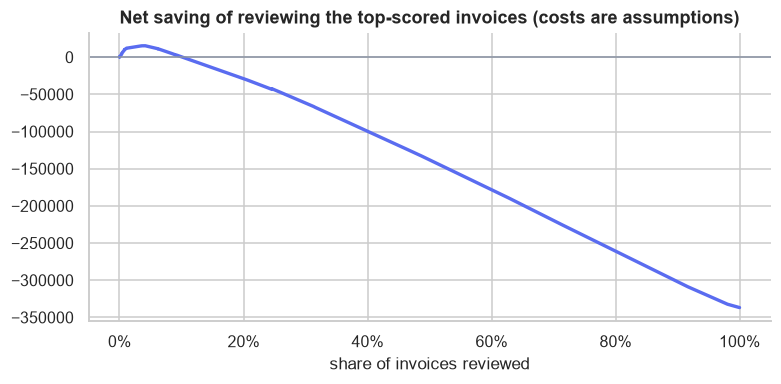

In [13]:
curve = q("select * from analytics.alert_cost_curve")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(curve["share_reviewed"], curve["net_saving_eur"], color=COBALT, lw=2.2)
ax.axhline(0, color=GREY, lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("share of invoices reviewed")
ax.set_title("Net saving of reviewing the top-scored invoices (costs are assumptions)")
save(fig, "model_cost_curve")
m["alerts"]["assumptions"], m["alerts"]["best"]

A good AUC doesn't mean a model is worth deploying. Reviewing pays only where the chance of catching
a correction beats review cost ÷ (correction cost × share prevented). With a €10 check the sensible
review share is a small slice of invoices; at €25 the saving falls to about €5k on 0.8% of them. Those costs are assumptions, which
is why the dashboard lets the reader change them.

### Anomaly detection
An Isolation Forest never sees the control rules, so its agreement with them is independent
evidence that it's finding something real.

In [14]:
pd.DataFrame([m["alerts"]["anomaly"]]).T

,0
base_rate_rules,0.070634
precision_at_500,0.584000
precision_at_2500,0.478800
precision_at_10000,0.350700


In [15]:
con.close()